# Exploratory analysis of the dataset

In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import torch

from src.dataset import load_labeled_works

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(device)

cuda


In [10]:

df = load_labeled_works()
df

retraction watch papers with doi : 61843
7878 papers from the retraction watch matched with works data


,id,doi,year,title,abstract,source,authors,refs,referenced,topics,keywords,type,is_retracted,requested_id,record_origin,paper_mill,peer_review,referencing,manipulation,high_label_journal
0,W3091073766,10.1007/s00500-020-05330-8,2020.0,Computational procedure for solving fuzzy equa...,,S65753830,"[A5072607417, A5073095019]","[W1180578182, W1898259180, W1986562360, W20119...",9,"[{'id': 'https://openalex.org/T12135', 'score'...","[fuzzy equations, fuzzy arithmetic, fuzzy set ...",article,False,W3091073766,reference,False,False,False,False,True
1,W4288884797,10.1155/2022/5708652,2022.0,Advanced Artificial Intelligence Model for Fin...,Machine learning belongs to the science of art...,S152111507,[A5004438602],"[W2528598423, W2569349941, W2576683119, W25872...",11,"[{'id': 'https://openalex.org/T13910', 'score'...","[financial accounting, unstructured text, corp...",article,False,W4288884797,reference,False,False,False,False,True
2,W3037084301,10.1155/2020/6540167,2020.0,Design of Stable Controller for Flexible Solar...,Flexible solar panels play an essential role i...,S207319443,"[A5076658021, A5051110858, A5068723830, A50763...","[W1977291138, W2029104169, W2059527156, W20650...",3,"[{'id': 'https://openalex.org/T11096', 'score'...","[flexible solar panels, H-infinity loop shapin...",article,False,W3037084301,reference,False,False,False,False,True
3,W2920046867,10.1016/j.ins.2019.03.002,2019.0,Cryptanalysis of a public authentication proto...,,S192650101,"[A5049151787, A5082041657, A5012016098, A50509...","[W44164607, W89553247, W1994788755, W210288129...",13,"[{'id': 'https://openalex.org/T11614', 'score'...","[cryptanalysis, outsourced databases, cloud co...",article,False,W2920046867,reference,False,False,False,False,False
4,W3071522575,10.1016/j.ins.2020.08.052,2020.0,An incremental density-based clustering framew...,,S192650101,"[A5084312149, A5014047641]","[W174812315, W1530595269, W1532325895, W156574...",60,"[{'id': 'https://openalex.org/T10637', 'score'...","[incremental clustering, density-based cluster...",article,False,W3071522575,reference,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
951276,W2909885546,10.1016/j.aml.2018.12.014,2019.0,Darboux transformation and explicit solutions ...,,S7571225,[A5101737106],"[W1610441017, W1999786383, W2010599738, W20277...",17,"[{'id': 'https://openalex.org/T10248', 'score'...","[Darboux transformation, nonlocal Schrödinger ...",article,False,W2909885546,reference,False,False,False,False,False
951277,W2471951217,10.1111/jiec.12446,2016.0,GIS‐based Analysis of Vienna's Material Stock ...,,S203731762,"[A5089980173, A5011265003, A5005021710, A50298...","[W598268993, W1515545408, W1567277510, W188403...",251,"[{'id': 'https://openalex.org/T12643', 'score'...","[building material stock, material intensity, ...",article,False,W2471951217,reference,False,False,False,False,False
951278,W4300553627,10.1007/978-3-642-27848-8_722-1,2014.0,Frequent Pattern Mining,,S4306463937,[A5076101253],"[W1530375089, W2012509730, W2030996579, W20648...",61,"[{'id': 'https://openalex.org/T10538', 'score'...","[frequent pattern mining, frequent itemsets, a...",reference-entry,False,W4300553627,reference,False,False,False,False,False
951279,W3159946074,10.22271/allresearch.2021.v7.i4c.8484,2021.0,Hierarchical Clustering: A Survey,There is a need to scrutinise and retrieve inf...,S2764689006,[A5028130514],"[W71676260, W1523937437, W2066680326, W2119018...",85,"[{'id': 'https://openalex.org/T10637', 'score'...","[hierarchical clustering, partitional clusteri...",article,False,W3159946074,reference,False,False,False,False,False


In [43]:
print(df["refs"].apply(len).min())
print(df["refs"].apply(len).mean())
print(df["refs"].apply(len).max())

print((df["manipulation"] == True).sum())

print(df["source"].value_counts())
print(df["high_label_journal"].value_counts())

0
35.265880428601015
5000
5305
source
               22090
S106296714     17885
S2485537415    13019
S4306400194    11284
S178238111     11202
               ...  
S4210179064        1
S7407105020        1
S4210221639        1
S4210180506        1
S92925526          1
Name: count, Length: 36977, dtype: int64
high_label_journal
False    901418
True      49863
Name: count, dtype: int64


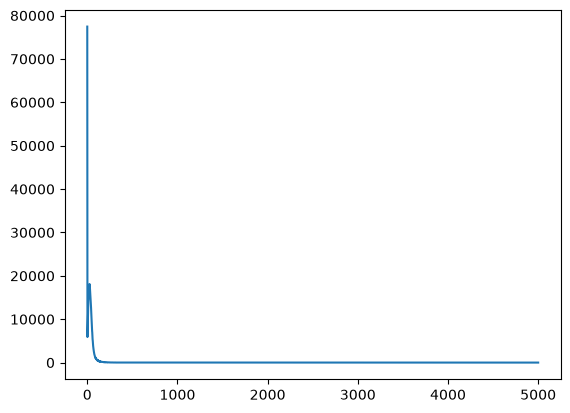

In [4]:
plt.plot(df["refs"].apply(len).value_counts().sort_index())
# plt.axis((0,100,0,100))
plt.show()


In [3]:
def filter_rows(df: pd.DataFrame) -> pd.Series:
    """Filtering criterion for accepting papers in the graph."""
    return (
        (df["manipulation"] == False)
        & (df["title"] != "")
        & (df["title"] != np.nan)
        # & (df["abstract"] != "" )
        # & (df["high_label_journal"] == True)
        # & (df["abstract"].apply(lambda abstract: "retracted" not in abstract))
    )


In [ ]:
graph_df = df[filter_rows(df)].set_index("id")
graph_df = graph_df.drop(columns=["requested_id", "record_origin"])

In [4]:
from typing import Callable

def create_graph(filtered_df: pd.DataFrame, keep_internal_references_only: bool) -> nx.DiGraph:
    """
    Creates a networkx directed graph from the papers in the dataframe.
    Filters papers to add to the graph by using the given filtering function.
    """

    graph = nx.DiGraph()

    for index, row in filtered_df.iterrows():
        graph.add_node(index)

    for index, row in filtered_df.iterrows():
        for ref in row["refs"]:
            if not keep_internal_references_only or ref in graph.nodes: # important choice : do we accept adding new edges with papers that are not already in the graph ? 
                graph.add_edge(index, ref)

    return graph


In [79]:
graph = create_graph(graph_df, keep_internal_references_only=True)

print(graph)


DiGraph with 945799 nodes and 13540258 edges


In [9]:
components = list(sorted(nx.strongly_connected_components(graph), key=len, reverse=True))
print(len(list(components)))

# for cc in components:
#     print(graph.subgraph(cc))

594871


The citation graph is basically acyclic, it has no major strongly connected component. We can work with the biggest weakly connected component instead, by leaving out only a small fraction of nodes.

In [10]:
max_component = graph.subgraph(max(nx.weakly_connected_components(graph), key=len))
print(max_component)

DiGraph with 934826 nodes and 13542227 edges


## Degree distribution

1         57214
2        214647
3        114915
4         77663
5         57562
          ...  
20845         0
20846         0
20847         0
20848         0
20849         1
Name: count, Length: 20849, dtype: int64


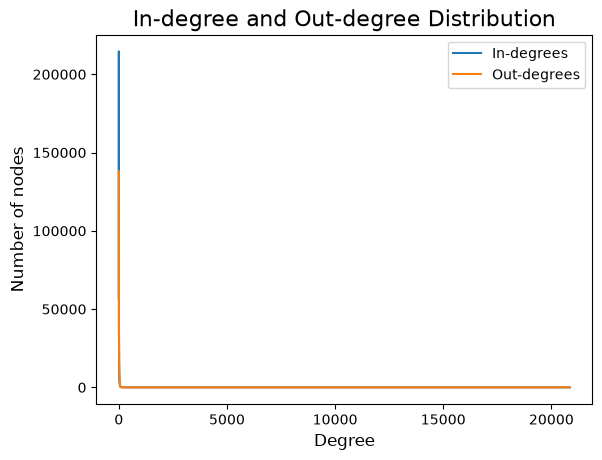

In [19]:
in_degrees: list[tuple[str, int]] = graph.in_degree
out_degrees: list[tuple[str, int]] = graph.out_degree

max_degree = max(list(in_degrees) + list(out_degrees), key=lambda degree: degree[1])[1]
degrees = pd.Series(range(1, max_degree+2))

# Convert in_degrees and out_degrees to pandas Series
in_degrees_series = pd.Series([degree[1] for degree in in_degrees]) +1 
out_degrees_series = pd.Series([degree[1] for degree in out_degrees]) +1 

# Count occurrences of each degree
in_degrees_count = in_degrees_series.value_counts().sort_index().reindex(degrees, fill_value=0)
out_degrees_count = out_degrees_series.value_counts().sort_index().reindex(degrees, fill_value=0)


print(in_degrees_count)

plt.plot(in_degrees_count, label="In-degrees")
plt.plot(out_degrees_count, label="Out-degrees")
plt.title("In-degree and Out-degree Distribution", fontsize=16)
plt.xlabel("Degree", fontsize=12)
plt.ylabel("Number of nodes", fontsize=12)
# plt.axis((5, 100, 0, 2000))

plt.legend()
plt.show()

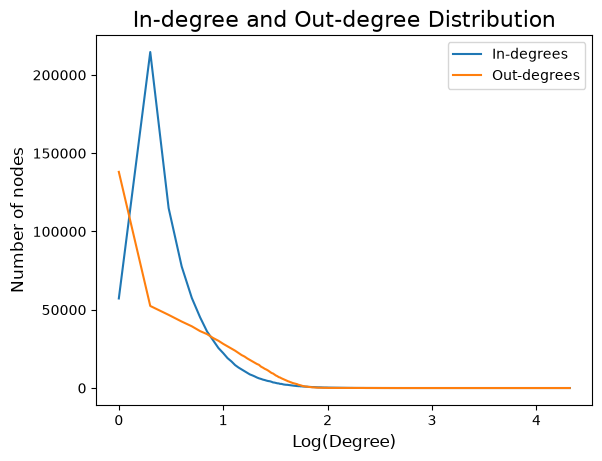

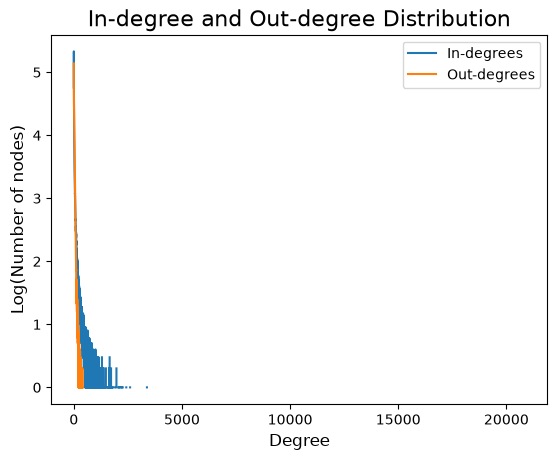

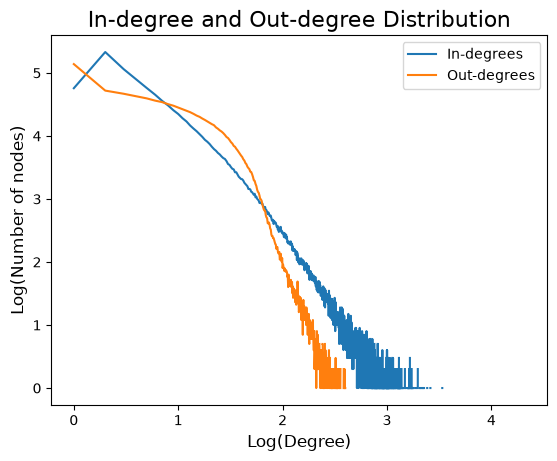

In [20]:
log_in_degrees_count = in_degrees_count.apply(np.log10)
log_out_degrees_count = out_degrees_count.apply(np.log10)
log_degrees = degrees.apply(np.log10)

plt.plot(log_degrees, in_degrees_count, label="In-degrees")
plt.plot(log_degrees, out_degrees_count, label="Out-degrees")
plt.title("In-degree and Out-degree Distribution", fontsize=16)
plt.xlabel("Log(Degree)", fontsize=12)
plt.ylabel("Number of nodes", fontsize=12)
plt.legend()

plt.show()
plt.plot(degrees, log_in_degrees_count, label="In-degrees")
plt.plot(degrees, log_out_degrees_count, label="Out-degrees")
plt.title("In-degree and Out-degree Distribution", fontsize=16)
plt.xlabel("Degree", fontsize=12)
plt.ylabel("Log(Number of nodes)", fontsize=12)
plt.legend()
plt.show()

plt.plot(log_degrees, log_in_degrees_count, label="In-degrees")
plt.plot(log_degrees, log_out_degrees_count, label="Out-degrees")
plt.title("In-degree and Out-degree Distribution", fontsize=16)
plt.xlabel("Log(Degree)", fontsize=12)
plt.ylabel("Log(Number of nodes)", fontsize=12)
plt.legend()
plt.show()

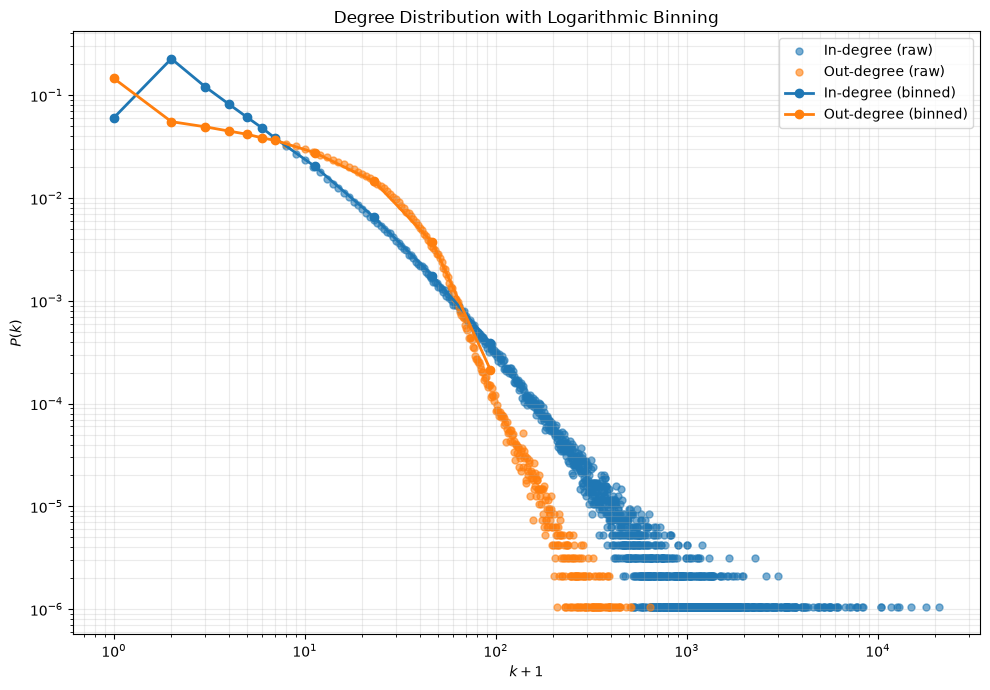

In [21]:
# ----------------------------
# Raw degree distributions
# ----------------------------

in_degree_values = np.array([degree for _, degree in in_degrees])
out_degree_values = np.array([degree for _, degree in out_degrees])

n = len(in_degree_values)

max_degree = max(
    in_degree_values.max(),
    out_degree_values.max()
)

# Count every degree, including degrees that don't occur
in_counts = (
    pd.Series(in_degree_values)
    .value_counts()
    .reindex(range(max_degree + 1), fill_value=0)
)

out_counts = (
    pd.Series(out_degree_values)
    .value_counts()
    .reindex(range(max_degree + 1), fill_value=0)
)


# ----------------------------
# Binning
# ----------------------------

# Bins are defined in u = k + 1
bin_edges = [1, 2, 3, 4, 5, 6, 7, 8, 16, 32, 64, 128]


def bin_distribution(counts, bin_edges, n):
    """
    Bin a degree distribution using the course's scheme.

    Returns:
        x: geometric mean of degrees in each bin (using k + 1)
        y: normalized count per unit bin width
    """
    x = []
    y = []

    for left, right in zip(bin_edges[:-1], bin_edges[1:]):

        # u = k + 1
        # Therefore k = u - 1
        degrees_in_bin = np.arange(left, right) - 1

        # Don't include degrees outside our actual distribution
        degrees_in_bin = degrees_in_bin[
            degrees_in_bin <= counts.index.max()
        ]

        if len(degrees_in_bin) == 0:
            continue

        # Number of nodes whose degree falls in this bin
        count = counts.loc[degrees_in_bin].sum()

        # IMPORTANT:
        # Normalize by the bin's width, NOT by the number of
        # observed degrees/nodes in the bin.
        width = right - left

        y.append(count / n / width)

        # Geometric mean of the u values covered by the bin
        u_values = np.arange(left, right)
        x.append(np.exp(np.mean(np.log(u_values))))

    return np.array(x), np.array(y)


in_bin_x, in_bin_y = bin_distribution(
    in_counts,
    bin_edges,
    n
)

out_bin_x, out_bin_y = bin_distribution(
    out_counts,
    bin_edges,
    n
)


# ----------------------------
# Raw distributions
# ----------------------------

# Raw P(k), shifted to k + 1
raw_x = np.arange(max_degree + 1) + 1

in_raw_y = in_counts.values / n
out_raw_y = out_counts.values / n


# ----------------------------
# Plot
# ----------------------------

plt.figure(figsize=(10, 7))

# Raw points
plt.scatter(
    raw_x,
    in_raw_y,
    s=25,
    alpha=0.6,
    label="In-degree (raw)"
)

plt.scatter(
    raw_x,
    out_raw_y,
    s=25,
    alpha=0.6,
    label="Out-degree (raw)"
)

# Binned distributions
plt.plot(
    in_bin_x,
    in_bin_y,
    marker="o",
    linewidth=2,
    label="In-degree (binned)"
)

plt.plot(
    out_bin_x,
    out_bin_y,
    marker="o",
    linewidth=2,
    label="Out-degree (binned)"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"$k+1$")
plt.ylabel(r"$P(k)$")
plt.title("Degree Distribution with Logarithmic Binning")

plt.legend()
plt.grid(True, which="both", alpha=0.25)

plt.tight_layout()
plt.show()

In [22]:
# report on how much of the graph is usable for text analysis
usable_titles = 0
nodes_number = len(graph.nodes)
df_indexed = df.set_index("id")

for node in graph.nodes:
    title = str(df_indexed.loc[node]["title"])
    if title != "":
        usable_titles += 1

assert usable_titles == nodes_number, "Some titles are missing from the nodes in the graph, so the textual analysis is not possible."

## Textual analysis 

### Title proximity

In [5]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# A model optimized for semantic similarity
model = SentenceTransformer("all-mpnet-base-v2", device=device)

# model.compile()

c:\Users\aurel\repos\social_networks_project\finalproj\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 869.01it/s]


In [6]:
def encode_long_document_tokenized(text: str, model: SentenceTransformer, max_tokens=250) -> np.ndarray:
    """
    Encodes a document by splitting it into chunks to avoid truncation.
    Then averages the chunk vector with respect to token length to give a better final representation.
    The final embedding is the normalized.
    """
    
    tokenizer = model.tokenizer
    tokens = tokenizer(
        text,
        add_special_tokens=False,
        truncation=False,
        return_attention_mask=False
    )["input_ids"]

    embeddings = []
    weights = []

    for i in range(0, len(tokens), max_tokens):
        chunk_tokens = tokens[i:i + max_tokens]
        assert (len(chunk_tokens) <= max_tokens)
        chunk_text = tokenizer.decode(chunk_tokens, skip_special_tokens=True)
        emb = model.encode(chunk_text, convert_to_numpy=True)
        embeddings.append(emb)
        weights.append(len(chunk_tokens))

    final_embedding = np.average(
        embeddings,
        axis=0,
        weights=weights
    )

    return final_embedding / np.linalg.norm(final_embedding)


def encode_title(text: str, model: SentenceTransformer, max_tokens=250) -> np.ndarray:
    embedding = model.encode(text)
    return embedding / np.linalg.norm(embedding)

In [ ]:
title1 = graph_df["title"].iloc[6] 
title2 = graph_df["title"].iloc[1] 
print(title1)
print(title2)
# embeddings = encode_long_document_tokenized([, graph_df["title"][1]], model, max_tokens=250)

# Cosine similarity
similarity = cosine_similarity(
    [encode_title(title1, model)],
    [encode_title(title2, model)]
)[0][0]


print(f"Similarity: {similarity:.4f}")

Nonstationary fuzzy neural network based on FCMnet clustering and a modified CG method with Armijo-type rule
Advanced Artificial Intelligence Model for Financial Accounting Transformation Based on Machine Learning and Enterprise Unstructured Text Data
Similarity: 0.1957


In [ ]:
embeddings = model.encode(graph_df["title"].to_numpy(), show_progress_bar=True)


Batches: 100%|██████████| 29557/29557 [19:58<00:00, 24.66it/s]  


In [59]:
embeddings.shape

(945799, 768)

In [7]:
def edge_similarity_score(edge: tuple[str, str], graph_df: pd.DataFrame, embeddings: np.ndarray):
    try:
        embedding_u = embeddings[graph_df.index.get_loc(edge[0])]
        embedding_v = embeddings[graph_df.index.get_loc(edge[1])]
    except (IndexError, KeyError):
        return np.nan
        # return float(cosine_similarity([embedding_u], [embedding_v])[0][0])

    # because embeddings are normalized, we can speed up the cosine similarity computation
    return np.dot(embedding_u, embedding_v)

def graph_similarity_scores(graph: nx.DiGraph, graph_df: pd.DataFrame, embeddings: np.ndarray) -> dict[tuple[str,str],float]:
    """
    For each edge of the graph linking 2 papers with abstracts, computes the similarity score.
    """

    similarity_scores: dict[tuple[str,str],float] = dict()

    n_edges = len(graph.edges)
    processed_count = 0
    for edge in graph.edges:
        similarity_scores[edge] = edge_similarity_score(edge, graph_df, embeddings)
        processed_count += 1
        print(f"Computed similarity by edge : {processed_count} / {n_edges}", end="\r")
    return similarity_scores

def plot_similarity_scores(similarity_scores: dict[tuple[str,str],float], label: str):
    plt.hist(list(similarity_scores.values()), bins=50, range=(-1,1))
    plt.xlabel(label)
    plt.xlim(-1,1)
    plt.show()

In [81]:
similarity_scores = graph_similarity_scores(graph, graph_df, embeddings)

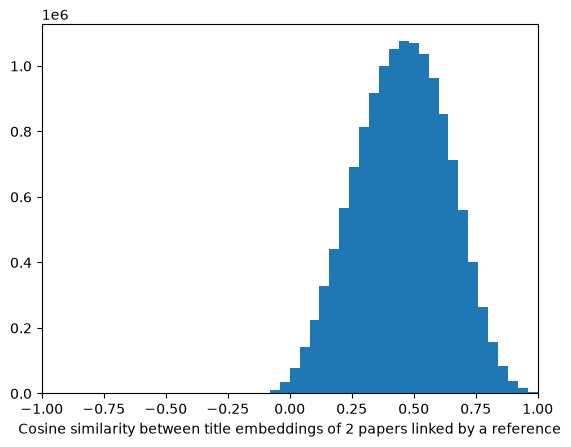

In [ ]:
plot_similarity_scores(similarity_scores, "Cosine similarity between title embeddings of 2 papers linked by a reference")

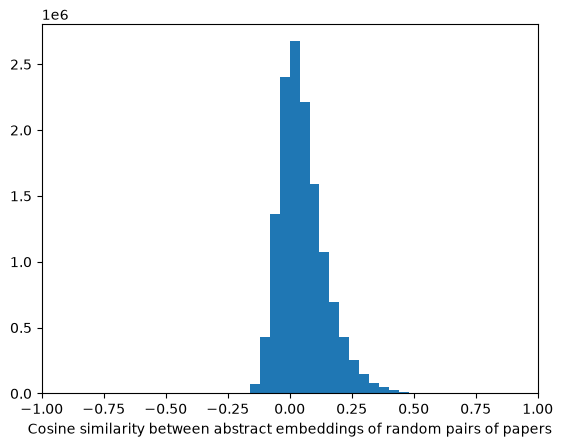

In [63]:
# first null model : similarity between randomly sampled pairs of papers
# the second null model should be a configuration model of the first graph, so the same papers are used, just different pairs

n_edges = len(graph.edges)
processed_count = 0
similarity_scores_random: dict[tuple[str,str],float] = dict()

for i in range(n_edges):
    node_u = np.random.choice(graph_df.index)
    node_v = np.random.choice(graph_df.index)
    false_edge = (node_u, node_v)
    if node_u == node_v or false_edge in graph.edges:
        i-=1
        continue

    similarity_scores_random[false_edge] = edge_similarity_score(false_edge, graph_df, embeddings)

    processed_count += 1
    print(f"Computed similarity by fake random edge : {processed_count} / {n_edges}", end="\r")

plot_similarity_scores(similarity_scores_random, "Cosine similarity between abstract embeddings of random pairs of papers")
   

In [13]:
configuration_model_graph = nx.double_edge_swap(
    graph.copy().to_undirected(),
    nswap=2*graph.number_of_edges(),
    max_tries=5*graph.number_of_edges(),
)

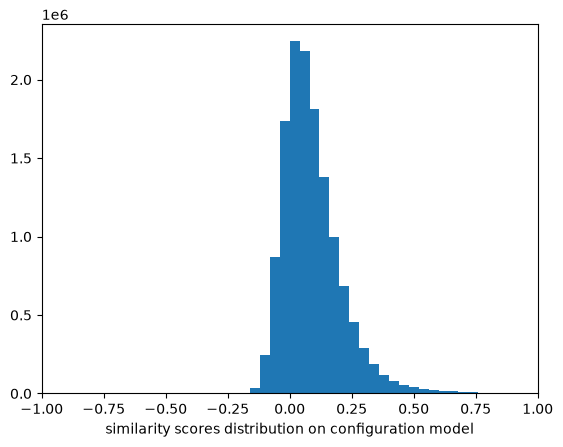

In [14]:
similarity_scores_config = graph_similarity_scores(configuration_model_graph, graph_df, embeddings)
plot_similarity_scores(similarity_scores_config, "similarity scores distribution on configuration model")

In [21]:
# Now checking the underlying distribution of similarity par paper instead of per edge

def paper_avg_citation_similarity(paper_id: str, graph: nx.DiGraph, similarity_scores: dict[tuple[str, str], float]) -> float:
    paper_similarities = list()
    for edge in graph.edges(paper_id):
        similarity = similarity_scores[edge]
        paper_similarities.append(similarity)

    return np.average(paper_similarities)

def paper_min_citation_similarity(paper_id: str, graph: nx.DiGraph, similarity_scores: dict[tuple[str, str], float]) -> float:
    paper_similarities = list()
    for edge in graph.edges(paper_id):
        similarity = similarity_scores[edge]
        paper_similarities.append(similarity)

    if len(paper_similarities) == 0:
        return np.nan

    return np.min(paper_similarities)

def paper_max_citation_similarity(paper_id: str, graph: nx.DiGraph, similarity_scores: dict[tuple[str, str], float]) -> float:
    paper_similarities = list()
    for edge in graph.edges(paper_id):
        similarity = similarity_scores[edge]
        paper_similarities.append(similarity)

    if len(paper_similarities) == 0:
        return np.nan

    return np.max(paper_similarities)

c:\Users\aurel\repos\social_networks_project\finalproj\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:588: RuntimeWarning: Mean of empty slice
  avg = a.mean(axis, **keepdims_kw)
c:\Users\aurel\repos\social_networks_project\finalproj\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


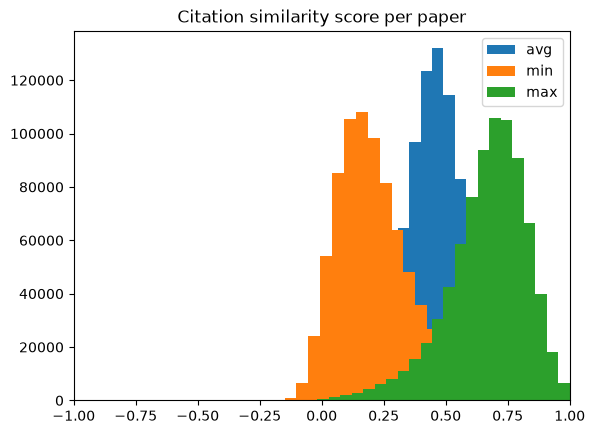

In [88]:
plt.hist(graph_df.index.to_series().apply(paper_avg_citation_similarity, graph=graph, similarity_scores=similarity_scores), bins=25, label="avg")
plt.hist(graph_df.index.to_series().apply(paper_min_citation_similarity, graph=graph, similarity_scores=similarity_scores), bins=25, label="min")
plt.hist(graph_df.index.to_series().apply(paper_max_citation_similarity, graph=graph, similarity_scores=similarity_scores), bins=25, label="max")
plt.title("Citation similarity score per paper")
plt.xlim(-1,1)
plt.legend()
plt.show()

### Retracted papers

In [11]:
def filter_rows_manipulation(df: pd.DataFrame) -> pd.Series:
    """Filtering criterion for accepting papers in the graph."""
    return (
        (df["manipulation"] == True)
        & (df["title"] != "")
        & (df["title"] != np.nan)
    )
    

manipulation_df = df[filter_rows_manipulation(df)].set_index("id")

In [12]:
manipulation_centered_graph = create_graph(manipulation_df, keep_internal_references_only=False)

In [13]:
print(manipulation_centered_graph)

DiGraph with 119310 nodes and 141722 edges


In [14]:
manipulation_df = df[df["id"].isin(manipulation_centered_graph.nodes)].set_index("id")
manipulation_df.shape

(103896, 19)

In [15]:
manipulation_df["title"] = manipulation_df["title"].str.replace("RETRACTED:", "")

In [16]:
manipulation_embeddings = model.encode(manipulation_df["title"].to_numpy(), show_progress_bar=True)

Batches: 100%|██████████| 3247/3247 [02:15<00:00, 24.01it/s]


In [17]:
manipulation_similarity_scores = graph_similarity_scores(manipulation_centered_graph, manipulation_df, manipulation_embeddings)

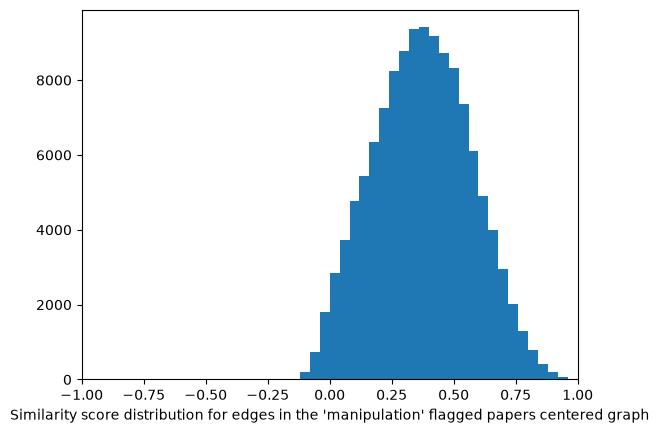

In [52]:
plot_similarity_scores(manipulation_similarity_scores, label="Similarity score distribution for edges in the 'manipulation' flagged papers centered graph")

c:\Users\aurel\repos\social_networks_project\finalproj\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:588: RuntimeWarning: Mean of empty slice
  avg = a.mean(axis, **keepdims_kw)
c:\Users\aurel\repos\social_networks_project\finalproj\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


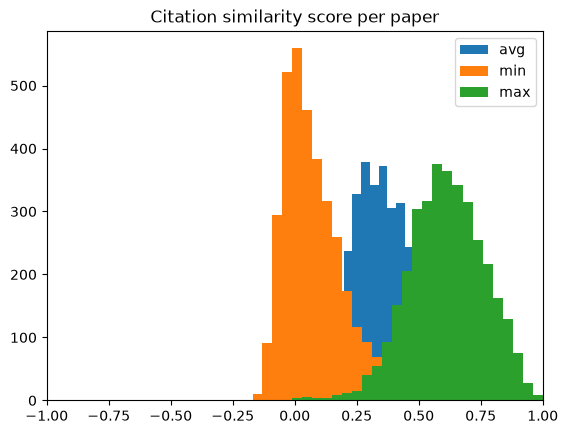

In [ ]:
plt.hist(manipulation_df.index.to_series().apply(paper_avg_citation_similarity, graph=manipulation_centered_graph, similarity_scores=manipulation_similarity_scores), bins=25, label="avg")
plt.hist(manipulation_df.index.to_series().apply(paper_min_citation_similarity, graph=manipulation_centered_graph, similarity_scores=manipulation_similarity_scores), bins=25, label="min")
plt.hist(manipulation_df.index.to_series().apply(paper_max_citation_similarity, graph=manipulation_centered_graph, similarity_scores=manipulation_similarity_scores), bins=25, label="max")
plt.title("Citation similarity score per paper")
plt.xlim(-1,1)
plt.legend()
plt.show()

In [90]:
# plt.hist(manipulation_df.index.to_series().apply(paper_avg_citation_similarity, graph=manipulation_centered_graph, similarity_scores=manipulation_similarity_scores), bins=25, label="manipulation_avg", histtype="step")
# plt.hist(manipulation_df.index.to_series().apply(paper_min_citation_similarity, graph=manipulation_centered_graph, similarity_scores=manipulation_similarity_scores), bins=25, label="manipulation_min", histtype="step")
# plt.hist(manipulation_df.index.to_series().apply(paper_max_citation_similarity, graph=manipulation_centered_graph, similarity_scores=manipulation_similarity_scores), bins=25, label="manipulation_max", histtype="step")

# plt.hist(graph_df.index.to_series().apply(paper_avg_citation_similarity, graph=graph, similarity_scores=similarity_scores), bins=25, label="avg", histtype="step")
# plt.hist(graph_df.index.to_series().apply(paper_min_citation_similarity, graph=graph, similarity_scores=similarity_scores), bins=25, label="min", histtype="step")
# plt.hist(graph_df.index.to_series().apply(paper_max_citation_similarity, graph=graph, similarity_scores=similarity_scores), bins=25, label="max", histtype="step")
# plt.title("Citation similarity score per paper")
# plt.xlim(-1,1)
# plt.legend()
# plt.show()

In [22]:
manipulation_papers_similarities = pd.concat(
    [
        manipulation_df.index.to_series().apply(paper_avg_citation_similarity, graph=manipulation_centered_graph, similarity_scores=manipulation_similarity_scores).to_frame("avg_citation_similarity"),
        manipulation_df.index.to_series().apply(paper_min_citation_similarity, graph=manipulation_centered_graph, similarity_scores=manipulation_similarity_scores).to_frame("min_citation_similarity"),
        manipulation_df.index.to_series().apply(paper_max_citation_similarity, graph=manipulation_centered_graph, similarity_scores=manipulation_similarity_scores).to_frame("max_citation_similarity"),
    ],
    axis=1
).dropna().join(manipulation_df)

c:\Users\aurel\repos\social_networks_project\finalproj\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:588: RuntimeWarning: Mean of empty slice
  avg = a.mean(axis, **keepdims_kw)
c:\Users\aurel\repos\social_networks_project\finalproj\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [96]:
manipulation_papers_similarities["min_citation_similarity"].sort_values()


id
W4220918855   -0.170204
W4220957361   -0.157276
W4220952859   -0.144345
W4285745241   -0.138874
W4283020442   -0.137479
                 ...   
W3215800791    0.620257
W4283765355    0.662553
W4302024145    0.692973
W4280553358    0.711950
W3217362473    0.832453
Name: min_citation_similarity, Length: 3485, dtype: float64

In [97]:
manipulation_papers_similarities["avg_citation_similarity"].sort_values()


id
W4211219217   -0.049195
W4200535023   -0.028505
W4224306357   -0.010717
W4297262969   -0.010712
W4200263623   -0.007002
                 ...   
W2983374061    0.757553
W3203325752    0.771575
W4306748471    0.794474
W4280553358    0.795593
W3217362473    0.832453
Name: avg_citation_similarity, Length: 3485, dtype: float64

In [23]:
manipulation_papers_similarities["max_citation_similarity"].sort_values()

id
W4297262969   -0.010712
W4200263623   -0.007002
W4200535023    0.008082
W4224306357    0.047445
W4200088299    0.051334
                 ...   
W4213435098    0.972723
W2983374061    0.985872
W4293348988    0.986050
W4293255313    0.991410
W4220781188    1.000000
Name: max_citation_similarity, Length: 3485, dtype: float64

**W4211219217 was flagged by average citation similarity and is indeed very suspicious : it is about algorithms for improvement of tuberculosis detection and only cites relatively old papers about addictions and social sciences**

In [18]:
def plot_single_paper_similarity_scores(similarity_scores: dict[tuple[str,str],float], paper_id: str):

    paper_similarity = list()
    for edge, score in similarity_scores.items():
        if edge[0] == paper_id:
            paper_similarity.append(score)
    label = f"citation similarity distribution for paper {paper_id}"
    plt.hist(paper_similarity, bins=50, range=(-1,1))
    plt.xlabel(label)
    plt.xlim(-1,1)
    plt.show()

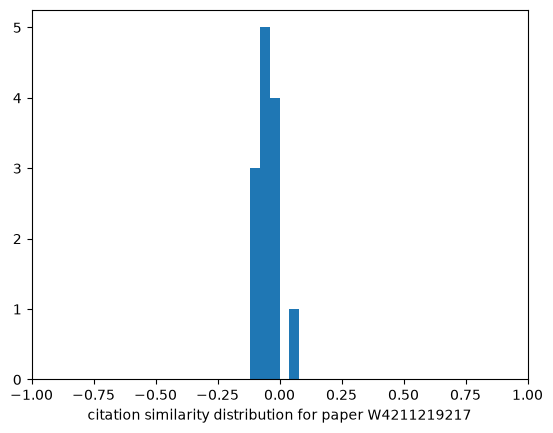

In [19]:
plot_single_paper_similarity_scores(manipulation_similarity_scores, "W4211219217")

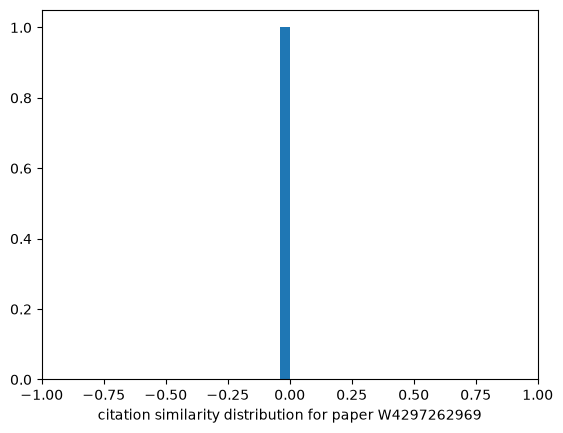

In [24]:

plot_single_paper_similarity_scores(manipulation_similarity_scores, "W4297262969")


### Keyword-based proximity

Alternatively, instead of using title embeddings, we could use the provided keywords for each paper and check similarity of edges.

## Graph analysis 

### Communities against topic label

Run Louvain and check how well the communities match with the known topics of papers. 

Then flag edges that cross communities or papers with a lot of external references.

Build a sample from the data with most important topics and retracted papers and run communities only on them.

In [15]:
# communities_louvain = nx.community.louvain_communities(graph, weight=None)
# way too long to compute

In [12]:
import igraph as ig
import leidenalg as la

# Convert NetworkX graph
graph_ig = ig.Graph.from_networkx(graph)

# Run Leiden
partition = la.find_partition(
    graph_ig,
    la.ModularityVertexPartition
)

# Community id for each node
membership = partition.membership

In [23]:
communities = {}

for node, comm in zip(graph_ig.vs["_nx_name"], membership):
    communities[node] = comm

In [ ]:
communities_df = pd.DataFrame.from_dict(communities, orient="index", columns=["community"])
communities_df["community"].value_counts()

community
0        111100
1        106373
2         93737
3         90405
4         61219
          ...  
10931         1
10932         1
10933         1
10934         1
10935         1
Name: count, Length: 10936, dtype: int64

In [35]:
graph_df = graph_df.merge(
    communities_df,
    left_index=True,
    right_index=True
)

### Authority score

Detect papers that mostly cite papers of low authority : their total referenced count from the data, not in-degree from the graph.

This is an alternative to the information PageRank could provide, but since we have a partial graph and lack lots of information about the peripheral nodes, actually running PageRank would provide unreliable results.

### Cartels detection

1. Create a graph of authors with edges having for weight the amount of mutual citations between them : min(citations(A->B), citations(B->A))
Detect edges with a high local value (authors co-referecing each other way more than with any other author)
2. Run Louvain to find bigger groups of authors co-referencing each other more than expected.


## Computed data saving and loading

In [72]:
dataframe_name = input("Filename to save the dataframe with embeddings as : ")

In [ ]:
# graph_df.to_parquet("dataframes/"+dataframe_name+".parquet")
graph_df.to_pickle("dataframes/"+dataframe_name+".pickle")

In [10]:
del graph_df

In [61]:
np.save(
    "dataframes/"+dataframe_name+"_embeddings.npy",
    embeddings
)

In [ ]:
del embeddings

In [75]:
graph_df = pd.read_pickle(f"dataframes/"+dataframe_name+".pickle")

In [73]:
embeddings = np.load("dataframes/"+dataframe_name+"_embeddings.npy")

In [11]:
import gc
gc.collect()

0

In [ ]:
# output ids for these main paperd to query them with additional data 

# import json
# with open("seeds_ids.txt", "w") as f:
#     f.write(json.dumps({"ids": df["id"].to_list()}, indent=4))

In [ ]:
# merging partial reference records

# with open("data/raw/openalex/works.jsonl", "w", encoding="utf-8", errors="replace") as output:
#     with open("data/refreshed/seeds_references.jsonl", encoding="utf-8", errors="replace") as seeds:
#         output.write(seeds.read())
#     print("seeds")
#     with open("data/refreshed/justin_references.jsonl", encoding="utf-8", errors="replace") as papers:
#         output.write(papers.read())
#     print("justin")
#     with open("data/refreshed/partner_references.jsonl", encoding="utf-8", errors="replace") as papers:
#         output.write(papers.read())
#     print("partner")

seeds
justin
partner


In [6]:
graph_df

,doi,year,title,abstract,source,authors,refs,referenced,topics,keywords,type,is_retracted,requested_id,record_origin,paper_mill,peer_review,referencing,manipulation,high_label_journal
id,,,,,,,,,,,,,,,,,,,
W3091073766,10.1007/s00500-020-05330-8,2020.0,Computational procedure for solving fuzzy equa...,,S65753830,"[A5072607417, A5073095019]","[W1180578182, W1898259180, W1986562360, W20119...",9,"[{'id': 'https://openalex.org/T12135', 'score'...","[fuzzy equations, fuzzy arithmetic, fuzzy set ...",article,False,W3091073766,reference,False,False,False,False,True
W4288884797,10.1155/2022/5708652,2022.0,Advanced Artificial Intelligence Model for Fin...,Machine learning belongs to the science of art...,S152111507,[A5004438602],"[W2528598423, W2569349941, W2576683119, W25872...",11,"[{'id': 'https://openalex.org/T13910', 'score'...","[financial accounting, unstructured text, corp...",article,False,W4288884797,reference,False,False,False,False,True
W3037084301,10.1155/2020/6540167,2020.0,Design of Stable Controller for Flexible Solar...,Flexible solar panels play an essential role i...,S207319443,"[A5076658021, A5051110858, A5068723830, A50763...","[W1977291138, W2029104169, W2059527156, W20650...",3,"[{'id': 'https://openalex.org/T11096', 'score'...","[flexible solar panels, H-infinity loop shapin...",article,False,W3037084301,reference,False,False,False,False,True
W2920046867,10.1016/j.ins.2019.03.002,2019.0,Cryptanalysis of a public authentication proto...,,S192650101,"[A5049151787, A5082041657, A5012016098, A50509...","[W44164607, W89553247, W1994788755, W210288129...",13,"[{'id': 'https://openalex.org/T11614', 'score'...","[cryptanalysis, outsourced databases, cloud co...",article,False,W2920046867,reference,False,False,False,False,False
W3071522575,10.1016/j.ins.2020.08.052,2020.0,An incremental density-based clustering framew...,,S192650101,"[A5084312149, A5014047641]","[W174812315, W1530595269, W1532325895, W156574...",60,"[{'id': 'https://openalex.org/T10637', 'score'...","[incremental clustering, density-based cluster...",article,False,W3071522575,reference,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
W2909885546,10.1016/j.aml.2018.12.014,2019.0,Darboux transformation and explicit solutions ...,,S7571225,[A5101737106],"[W1610441017, W1999786383, W2010599738, W20277...",17,"[{'id': 'https://openalex.org/T10248', 'score'...","[Darboux transformation, nonlocal Schrödinger ...",article,False,W2909885546,reference,False,False,False,False,False
W2471951217,10.1111/jiec.12446,2016.0,GIS‐based Analysis of Vienna's Material Stock ...,,S203731762,"[A5089980173, A5011265003, A5005021710, A50298...","[W598268993, W1515545408, W1567277510, W188403...",251,"[{'id': 'https://openalex.org/T12643', 'score'...","[building material stock, material intensity, ...",article,False,W2471951217,reference,False,False,False,False,False
W4300553627,10.1007/978-3-642-27848-8_722-1,2014.0,Frequent Pattern Mining,,S4306463937,[A5076101253],"[W1530375089, W2012509730, W2030996579, W20648...",61,"[{'id': 'https://openalex.org/T10538', 'score'...","[frequent pattern mining, frequent itemsets, a...",reference-entry,False,W4300553627,reference,False,False,False,False,False
